In [1]:
# Step 1: Load CoastSat shoreline dataset

import pandas as pd
from pathlib import Path

# Dataset location
data_path = Path(
    "../data/coastsat/"
    "KUALA_MERANG_regression_training_strict_2013_2024.csv"
)

# Load dataset
df = pd.read_csv(data_path)

print("=== COASTSAT SHORELINE DATASET ===")
print("Total records:", len(df))
print("Total transects:", df["Transect_ID"].nunique())
print("Year range:", df["Year"].min(), "-", df["Year"].max())

print("\nFirst 5 records:")
display(df.head())

=== COASTSAT SHORELINE DATASET ===
Total records: 40
Total transects: 4
Year range: 2013 - 2024

First 5 records:


,Transect,Transect_ID,Year,Count,Median_m,Min_m,Max_m,Std_m,Range_m,Previous_Median_m,Median_Jump_m,Review_Flag,Flag_High_Variation,Flag_Large_Yearly_Change,Flag_Low_Sample,Use_For_Model
0,1,1,2013,7,170.982629,158.600103,171.840183,6.083523,13.240079,NaN,NaN,NO_NUMERICAL_FLAG,0,0,0,1
1,1,1,2015,9,154.590119,129.866639,164.860657,10.472201,34.994019,172.667525,-18.077406,NO_NUMERICAL_FLAG,0,0,0,1
2,1,1,2018,6,139.037374,119.553394,144.122936,9.304824,24.569542,132.686744,6.350630,NO_NUMERICAL_FLAG,0,0,0,1
3,1,1,2019,7,132.789813,126.954604,142.471750,4.918155,15.517146,139.037374,-6.247561,NO_NUMERICAL_FLAG,0,0,0,1
4,1,1,2020,9,106.911861,92.048361,121.603561,9.878424,29.555200,132.789813,-25.877952,NO_NUMERICAL_FLAG,0,0,0,1


## Step 2: Data Quality Assessment

This step checks missing values, duplicate observations, and data-quality indicators before training the Linear Regression model.

In [2]:

# Step 2: Check dataset quality

print("=== DATA QUALITY ASSESSMENT ===")

# Important columns for shoreline prediction
required_columns = [
    "Transect_ID",
    "Year",
    "Median_m",
    "Count",
    "Std_m",
    "Range_m"
]

# Check missing values in required columns
print("\n1. Missing Values:")
print(df[required_columns].isnull().sum())

# Check duplicate observations
duplicates = df.duplicated(
    subset=["Transect_ID", "Year"]
).sum()

print("\n2. Duplicate Records:", duplicates)

# Check existing quality flags
print("\n3. Data Quality Flags:")
print(df["Review_Flag"].value_counts(dropna=False))

# Check records selected for training
print("\n4. Training Selection:")
print(df["Use_For_Model"].value_counts(dropna=False))

# Summarize observation quality by transect
print("\n5. Summary by Transect:")

summary = df.groupby("Transect_ID").agg(
    Records=("Year", "count"),
    Average_Samples=("Count", "mean"),
    Average_Std_m=("Std_m", "mean"),
    Maximum_Range_m=("Range_m", "max")
).round(2)

display(summary)

print("\n=== STEP 2 COMPLETED ===")


=== DATA QUALITY ASSESSMENT ===

1. Missing Values:
Transect_ID    0
Year           0
Median_m       0
Count          0
Std_m          0
Range_m        0
dtype: int64

2. Duplicate Records: 0

3. Data Quality Flags:
Review_Flag
NO_NUMERICAL_FLAG    40
Name: count, dtype: int64

4. Training Selection:
Use_For_Model
1    40
Name: count, dtype: int64

5. Summary by Transect:


,Records,Average_Samples,Average_Std_m,Maximum_Range_m
Transect_ID,,,,
1,9,6.33,7.56,34.99
2,11,7.64,6.53,34.34
3,12,7.33,5.71,27.73
4,8,7.50,6.91,39.62



=== STEP 2 COMPLETED ===


## Step 3: Five-Year Shoreline Prediction Backtest

This step trains Linear Regression using historical shoreline positions up to 2019 and predicts shoreline positions in 2024.

Predictions are compared with actual 2024 observations and a no-change baseline to evaluate forecasting performance.

In [3]:

# Step 3: Five-year Linear Regression backtest

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

results = []

TRAIN_END = 2019
TEST_YEAR = 2024

print("=== FIVE-YEAR SHORELINE PREDICTION ===")

for transect_id in sorted(df["Transect_ID"].unique()):

    # Select data for one transect
    data = df[df["Transect_ID"] == transect_id].copy()

    # Train using only years up to 2019
    train = data[data["Year"] <= TRAIN_END]
    test = data[data["Year"] == TEST_YEAR]

    # Require enough training data and a 2019 baseline
    baseline_row = train[train["Year"] == TRAIN_END]

    if len(train) < 3 or test.empty or baseline_row.empty:
        print(f"T{transect_id}: Insufficient data")
        continue

    # Train Linear Regression
    model = LinearRegression()

    model.fit(
        train[["Year"]],
        train["Median_m"]
    )

    # Predict 2024
    predicted = model.predict(
        pd.DataFrame({"Year": [TEST_YEAR]})
    )[0]

    # Actual 2024 measurement
    actual = test["Median_m"].iloc[0]

    # Baseline: shoreline does not move after 2019
    baseline = baseline_row["Median_m"].iloc[0]

    results.append({
        "Transect": transect_id,
        "Actual_2024_m": actual,
        "Predicted_2024_m": predicted,
        "LR_Error_m": abs(actual - predicted),
        "Baseline_Error_m": abs(actual - baseline),
        "Slope_m_per_year": model.coef_[0]
    })

# Display results
results_df = pd.DataFrame(results)

print("\n=== PREDICTION RESULTS ===")

if results_df.empty:
    print("No valid predictions available.")
else:
    display(results_df.round(2))

    # Calculate errors
    lr_mae = results_df["LR_Error_m"].mean()
    baseline_mae = results_df["Baseline_Error_m"].mean()

    print(f"Linear Regression MAE: {lr_mae:.2f} m")
    print(f"Baseline MAE: {baseline_mae:.2f} m")

    if lr_mae < baseline_mae:
        print("Result: Linear Regression performed better.")
    else:
        print("Result: Baseline performed as well or better.")

print("\n=== STEP 3 COMPLETED ===")


=== FIVE-YEAR SHORELINE PREDICTION ===

=== PREDICTION RESULTS ===


,Transect,Actual_2024_m,Predicted_2024_m,LR_Error_m,Baseline_Error_m,Slope_m_per_year
0,1,108.71,101.51,7.20,24.08,-6.17
1,2,87.31,57.14,30.17,10.86,-9.66
2,3,112.88,81.96,30.93,10.96,-10.30
3,4,136.11,132.08,4.04,15.68,-5.77


Linear Regression MAE: 18.08 m
Baseline MAE: 15.39 m
Result: Baseline performed as well or better.

=== STEP 3 COMPLETED ===


## Step 4: Five-Year Walk-Forward Validation

This step evaluates Linear Regression using multiple historical five-year prediction periods. Each model is trained only on observations available at the prediction starting year.

The results are compared against a no-change baseline to assess forecasting performance.

In [4]:

# Step 4: Five-year walk-forward validation

walkforward_results = []

FORECAST_HORIZON = 5

for transect_id in sorted(df["Transect_ID"].unique()):

    data = df[
        df["Transect_ID"] == transect_id
    ].sort_values("Year")

    # Try each available year as a forecast starting point
    for start_year in sorted(data["Year"].unique()):

        target_year = int(start_year) + FORECAST_HORIZON

        # Only test years with an actual observation
        target = data[data["Year"] == target_year]
        origin = data[data["Year"] == start_year]
        train = data[data["Year"] <= start_year]

        if len(train) < 3 or target.empty or origin.empty:
            continue

        model = LinearRegression()

        model.fit(
            train[["Year"]],
            train["Median_m"]
        )

        prediction = float(
            model.predict(
                pd.DataFrame({"Year": [target_year]})
            )[0]
        )

        actual = float(target["Median_m"].iloc[0])

        # No-change baseline at the forecast starting year
        baseline = float(origin["Median_m"].iloc[0])

        walkforward_results.append({
            "Transect": transect_id,
            "Start_Year": int(start_year),
            "Target_Year": target_year,
            "Actual_m": actual,
            "Predicted_m": prediction,
            "LR_Error_m": abs(actual - prediction),
            "Baseline_Error_m": abs(actual - baseline)
        })

wf_df = pd.DataFrame(walkforward_results)

print("=== FIVE-YEAR WALK-FORWARD VALIDATION ===")

if wf_df.empty:
    print("No eligible five-year test periods found.")

else:
    print("Total prediction tests:", len(wf_df))

    print("\nResults:")
    display(wf_df.round(2))

    print("\nAverage Error by Transect:")

    summary = wf_df.groupby("Transect")[
        ["LR_Error_m", "Baseline_Error_m"]
    ].mean().round(2)

    display(summary)

    print("\n=== OVERALL PERFORMANCE ===")

    lr_mae = wf_df["LR_Error_m"].mean()
    baseline_mae = wf_df["Baseline_Error_m"].mean()

    print(f"Linear Regression MAE: {lr_mae:.2f} m")
    print(f"Baseline MAE: {baseline_mae:.2f} m")

    if lr_mae < baseline_mae:
        print("Linear Regression performs better overall.")
    else:
        print("Baseline performs as well or better overall.")

print("\n=== STEP 4 COMPLETED ===")


=== FIVE-YEAR WALK-FORWARD VALIDATION ===
Total prediction tests: 13

Results:


,Transect,Start_Year,Target_Year,Actual_m,Predicted_m,LR_Error_m,Baseline_Error_m
0,1,2018,2023,109.59,106.62,2.98,29.44
1,1,2019,2024,108.71,101.51,7.20,24.08
2,2,2015,2020,70.29,88.29,18.01,66.50
3,2,2017,2022,78.13,87.48,9.35,52.01
4,2,2018,2023,84.02,79.82,4.19,36.66
5,2,2019,2024,87.31,57.14,30.17,10.86
6,3,2015,2020,100.92,91.88,9.03,60.83
7,3,2016,2021,127.84,130.44,2.60,47.79
8,3,2017,2022,113.40,120.42,7.02,45.84
9,3,2018,2023,137.87,108.28,29.58,10.67



Average Error by Transect:


,LR_Error_m,Baseline_Error_m
Transect,,
1,5.09,26.76
2,15.43,41.51
3,15.83,35.22
4,7.20,16.61



=== OVERALL PERFORMANCE ===
Linear Regression MAE: 12.73 m
Baseline MAE: 32.99 m
Linear Regression performs better overall.

=== STEP 4 COMPLETED ===


## Step 5: Prediction Performance by Year

This step examines how Linear Regression prediction errors change across historical evaluation years to identify periods of lower forecasting accuracy.

In [5]:

# Step 5: Evaluate prediction accuracy by target year

print("=== FIVE-YEAR PREDICTION ACCURACY BY YEAR ===")

yearly_performance = wf_df.groupby("Target_Year").agg(
    Total_Tests=("Transect", "count"),
    LR_MAE_m=("LR_Error_m", "mean"),
    Baseline_MAE_m=("Baseline_Error_m", "mean")
).round(2)

yearly_performance["Better_Method"] = (
    yearly_performance.apply(
        lambda row: "Linear Regression"
        if row["LR_MAE_m"] < row["Baseline_MAE_m"]
        else "Baseline",
        axis=1
    )
)

display(yearly_performance)

print("\n=== STEP 5 COMPLETED ===")


=== FIVE-YEAR PREDICTION ACCURACY BY YEAR ===


,Total_Tests,LR_MAE_m,Baseline_MAE_m,Better_Method
Target_Year,,,,
2020,2,13.52,63.67,Linear Regression
2021,1,2.60,47.79,Linear Regression
2022,3,8.91,38.47,Linear Regression
2023,3,12.25,25.59,Linear Regression
2024,4,18.08,15.39,Baseline



=== STEP 5 COMPLETED ===


## Step 6: Historical Shoreline Trend Visualization

This step visualizes the observed shoreline positions and compares them with Linear Regression trends trained using data from 2013–2019.


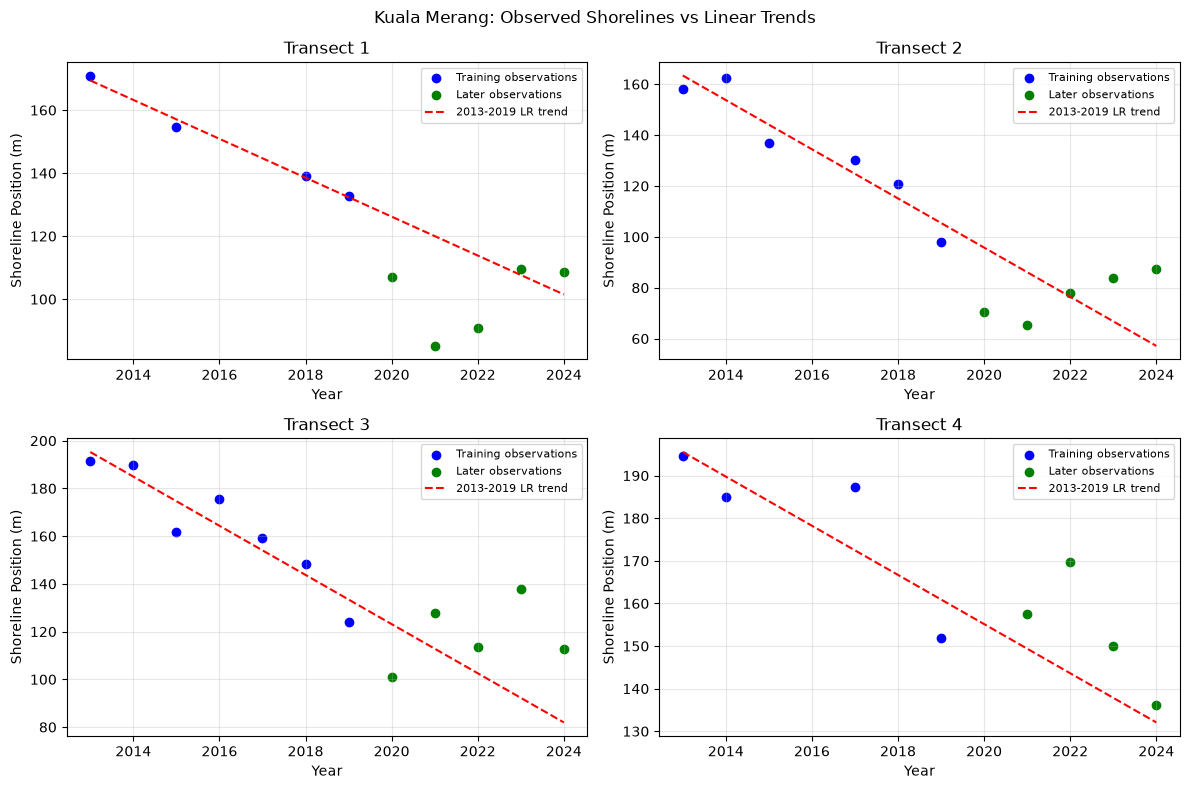

=== STEP 6 COMPLETED ===


In [6]:

# Step 6: Visualize shoreline trends

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for transect_id, ax in zip(
    sorted(df["Transect_ID"].unique()),
    axes.flatten()
):
    data = df[
        df["Transect_ID"] == transect_id
    ].sort_values("Year")

    train = data[data["Year"] <= 2019]
    later = data[data["Year"] > 2019]

    model = LinearRegression()
    model.fit(train[["Year"]], train["Median_m"])

    years = pd.DataFrame({
        "Year": range(2013, 2025)
    })

    predictions = model.predict(years)

    # Observed shoreline positions
    ax.scatter(
        train["Year"], train["Median_m"],
        color="blue", label="Training observations"
    )

    ax.scatter(
        later["Year"], later["Median_m"],
        color="green", label="Later observations"
    )

    # Historical regression trend extended to 2024
    ax.plot(
        years["Year"], predictions,
        color="red", linestyle="--",
        label="2013-2019 LR trend"
    )

    ax.set_title(f"Transect {transect_id}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Shoreline Position (m)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(
    "Kuala Merang: Observed Shorelines vs Linear Trends"
)
plt.tight_layout()
plt.show()

print("=== STEP 6 COMPLETED ===")


## Step 7: Comparison of Linear Regression Training Windows

This step compares full-history Linear Regression with a five-year training window using historical five-year forecasting tests. Both models are evaluated on the same eligible test cases.

In [7]:

# Step 7: Compare full-history and recent-window LR

comparison_results = []

for _, test in wf_df.iterrows():

    transect = test["Transect"]
    start_year = int(test["Start_Year"])
    target_year = int(test["Target_Year"])

    data = df[df["Transect_ID"] == transect]

    # All observations available at prediction time
    full_train = data[data["Year"] <= start_year]

    # Only observations from the latest 5 calendar years
    recent_train = full_train[
        full_train["Year"] >= start_year - 4
    ]

    # Require at least 3 observations for each model
    if len(recent_train) < 3:
        continue

    actual = float(
        data.loc[
            data["Year"] == target_year,
            "Median_m"
        ].iloc[0]
    )

    predictions = {}

    for name, training_data in [
        ("Full_History", full_train),
        ("Recent_5_Years", recent_train)
    ]:
        model = LinearRegression()
        model.fit(
            training_data[["Year"]],
            training_data["Median_m"]
        )

        predictions[name] = float(
            model.predict(
                pd.DataFrame({"Year": [target_year]})
            )[0]
        )

    comparison_results.append({
        "Transect": transect,
        "Start_Year": start_year,
        "Target_Year": target_year,
        "Full_History_Error_m": abs(
            actual - predictions["Full_History"]
        ),
        "Recent_5_Years_Error_m": abs(
            actual - predictions["Recent_5_Years"]
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("=== TRAINING WINDOW COMPARISON ===")
print("Comparable prediction tests:", len(comparison_df))

if not comparison_df.empty:

    summary = comparison_df.groupby("Transect")[
        [
            "Full_History_Error_m",
            "Recent_5_Years_Error_m"
        ]
    ].mean().round(2)

    display(summary)

    full_mae = comparison_df[
        "Full_History_Error_m"
    ].mean()

    recent_mae = comparison_df[
        "Recent_5_Years_Error_m"
    ].mean()

    print("\n=== OVERALL RESULTS ===")
    print(f"Full-history LR MAE: {full_mae:.2f} m")
    print(f"Recent-window LR MAE: {recent_mae:.2f} m")

    if recent_mae < full_mae:
        print("Recent-window LR performed better.")
    else:
        print("Full-history LR performed as well or better.")

print("\n=== STEP 7 COMPLETED ===")


=== TRAINING WINDOW COMPARISON ===
Comparable prediction tests: 11


,Full_History_Error_m,Recent_5_Years_Error_m
Transect,,
1.0,7.20,2.50
2.0,15.43,15.79
3.0,15.83,16.09
4.0,10.37,10.37



=== OVERALL RESULTS ===
Full-history LR MAE: 14.41 m
Recent-window LR MAE: 14.22 m
Recent-window LR performed better.

=== STEP 7 COMPLETED ===


## Step 8: Preliminary Shoreline Predictions for 2030 and 2035

This step generates experimental shoreline position predictions using Linear Regression. Models trained through 2024 and 2025 are compared to examine forecast sensitivity to the latest observations.

In [9]:

# Step 8: Preliminary 2030 and 2035 predictions

from pathlib import Path
import pandas as pd
from sklearn.linear_model import LinearRegression

# Load our existing 2025 observations
holdout_path = Path(
    "../data/coastsat/"
    "KUALA_MERANG_regression_holdout_2025.csv"
)

data_2025 = pd.read_csv(holdout_path)

columns = ["Transect_ID", "Year", "Median_m"]

# Training versions
data_until_2024 = df[columns].copy()

data_2025 = data_2025[columns].copy()
data_2025 = data_2025[data_2025["Year"] == 2025]

data_until_2025 = pd.concat(
    [data_until_2024, data_2025],
    ignore_index=True
)

# Check for duplicate measurements
assert not data_until_2025.duplicated(
    ["Transect_ID", "Year"]
).any(), "Duplicate transect-year records found!"

print("=== DATASET SUMMARY ===")
print("Training through 2024:", len(data_until_2024))
print("Training through 2025:", len(data_until_2025))

forecast_results = []

for transect_id in sorted(df["Transect_ID"].unique()):

    predictions = {}

    for version, dataset in [
        ("Through_2024", data_until_2024),
        ("Through_2025", data_until_2025)
    ]:

        training = dataset[
            dataset["Transect_ID"] == transect_id
        ]

        model = LinearRegression()

        model.fit(
            training[["Year"]],
            training["Median_m"]
        )

        future_years = pd.DataFrame({
            "Year": [2030, 2035]
        })

        future_positions = model.predict(future_years)

        predictions[version] = future_positions

    for index, year in enumerate([2030, 2035]):

        prediction_2024 = predictions[
            "Through_2024"
        ][index]

        prediction_2025 = predictions[
            "Through_2025"
        ][index]

        forecast_results.append({
            "Transect": transect_id,
            "Year": year,
            "Forecast_Through_2024_m": prediction_2024,
            "Forecast_Through_2025_m": prediction_2025,
            "Difference_m": abs(
                prediction_2024 - prediction_2025
            ),
            "Outside_Transect_Start": (
                prediction_2024 < 0
                or prediction_2025 < 0
            )
        })

forecast_df = pd.DataFrame(forecast_results)

print("\n=== PRELIMINARY SHORELINE FORECASTS ===")

display(forecast_df.round(2))

print("\n=== FORECAST CHECK ===")

print(
    "Forecasts extending beyond the transect start:",
    int(forecast_df["Outside_Transect_Start"].sum())
)

print("\nIMPORTANT:")
print("These are experimental projections.")
print("2025 data cover only part of the year.")
print("Tidal effects and measurement errors remain.")
print("The forecasts are not yet validated for future risk use.")

print("\n=== STEP 8 COMPLETED ===")


=== DATASET SUMMARY ===
Training through 2024: 40
Training through 2025: 44

=== PRELIMINARY SHORELINE FORECASTS ===


,Transect,Year,Forecast_Through_2024_m,Forecast_Through_2025_m,Difference_m,Outside_Transect_Start
0,1,2030,48.58,59.85,11.27,False
1,1,2035,13.77,29.47,15.71,False
2,2,2030,12.52,24.04,11.52,False
3,2,2035,-29.98,-14.10,15.87,True
4,3,2030,60.40,59.67,0.73,False
5,3,2035,23.50,22.49,1.01,False
6,4,2030,118.24,112.84,5.40,False
7,4,2035,96.03,88.62,7.41,False



=== FORECAST CHECK ===
Forecasts extending beyond the transect start: 1

IMPORTANT:
These are experimental projections.
2025 data cover only part of the year.
Tidal effects and measurement errors remain.
The forecasts are not yet validated for future risk use.

=== STEP 8 COMPLETED ===


In [ ]:
# Step 9: Export shoreline models for Flask integration

from pathlib import Path
import pandas as pd
import joblib
from sklearn.linear_model import LinearRegression

project_dir = Path(r"D:\FYP_Coastal_Erosion")

training_path = (
    project_dir / "data" / "coastsat" /
    "KUALA_MERANG_regression_training_strict_2013_2024.csv"
)

training = pd.read_csv(training_path)

training = training[
    training["Use_For_Model"].eq(1)
].copy()

assert not training.duplicated(
    ["Transect_ID", "Year"]
).any(), "Duplicate transect-year records found"

assert training[
    ["Transect_ID", "Year", "Median_m"]
].notna().all().all(), "Missing model inputs"

reference_year = 2024
forecast_years = [2030, 2035]

export_models = {}
reference_positions = {}
forecast_rows = []

for transect_id, records in training.groupby("Transect_ID"):
    transect_id = int(transect_id)
    records = records.sort_values("Year")

    reference = records[
        records["Year"].eq(reference_year)
    ]

    assert len(reference) == 1, (
        f"T{transect_id}: Expected one 2024 reference"
    )

    shoreline_model = LinearRegression()

    shoreline_model.fit(
        records[["Year"]],
        records["Median_m"]
    )

    reference_position = float(
        reference["Median_m"].iloc[0]
    )

    export_models[transect_id] = shoreline_model
    reference_positions[transect_id] = reference_position

    predicted_positions = shoreline_model.predict(
        pd.DataFrame({"Year": forecast_years})
    )

    for year, position in zip(
        forecast_years, predicted_positions
    ):
        position = float(position)

        forecast_rows.append({
            "Transect_ID": transect_id,
            "Reference_Year": reference_year,
            "Reference_Position_m": reference_position,
            "Forecast_Year": year,
            "Predicted_Position_m": position,
            "Change_From_Reference_m": (
                position - reference_position
            ),
            "Outside_Transect_Start": position < 0
        })

model_bundle = {
    "site": "Kuala Merang",
    "reference_year": reference_year,
    "trained_through_year": 2024,
    "target": "shoreline_position_along_transect_m",
    "axis_direction": "unverified",
    "models": export_models,
    "reference_positions_m": reference_positions
}

model_path = (
    project_dir / "models" /
    "kuala_merang_shoreline_lr.joblib"
)

forecast_path = (
    project_dir / "results" /
    "kuala_merang_shoreline_forecasts.csv"
)

model_path.parent.mkdir(parents=True, exist_ok=True)
forecast_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(model_bundle, model_path)

export_forecasts = pd.DataFrame(forecast_rows)
export_forecasts.to_csv(forecast_path, index=False)

print("Models saved:", len(export_models))
print("Forecast records:", len(export_forecasts))
print("Model:", model_path)
print("Forecasts:", forecast_path)

display(export_forecasts.round(2))

In [1]:
# Step 9: Export shoreline models for Flask integration

from pathlib import Path
import pandas as pd
import joblib
from sklearn.linear_model import LinearRegression

project_dir = Path(r"D:\FYP_Coastal_Erosion")

training_path = (
    project_dir / "data" / "coastsat" /
    "KUALA_MERANG_regression_training_strict_2013_2024.csv"
)

training = pd.read_csv(training_path)

training = training[
    training["Use_For_Model"].eq(1)
].copy()

assert not training.duplicated(
    ["Transect_ID", "Year"]
).any(), "Duplicate transect-year records found"

assert training[
    ["Transect_ID", "Year", "Median_m"]
].notna().all().all(), "Missing model inputs"

reference_year = 2024
forecast_years = [2030, 2035]

export_models = {}
reference_positions = {}
forecast_rows = []

for transect_id, records in training.groupby("Transect_ID"):
    transect_id = int(transect_id)
    records = records.sort_values("Year")

    reference = records[
        records["Year"].eq(reference_year)
    ]

    assert len(reference) == 1, (
        f"T{transect_id}: Expected one 2024 reference"
    )

    shoreline_model = LinearRegression()

    shoreline_model.fit(
        records[["Year"]],
        records["Median_m"]
    )

    reference_position = float(
        reference["Median_m"].iloc[0]
    )

    export_models[transect_id] = shoreline_model
    reference_positions[transect_id] = reference_position

    predicted_positions = shoreline_model.predict(
        pd.DataFrame({"Year": forecast_years})
    )

    for year, position in zip(
        forecast_years, predicted_positions
    ):
        position = float(position)

        forecast_rows.append({
            "Transect_ID": transect_id,
            "Reference_Year": reference_year,
            "Reference_Position_m": reference_position,
            "Forecast_Year": year,
            "Predicted_Position_m": position,
            "Change_From_Reference_m": (
                position - reference_position
            ),
            "Outside_Transect_Start": position < 0
        })

model_bundle = {
    "site": "Kuala Merang",
    "reference_year": reference_year,
    "trained_through_year": 2024,
    "target": "shoreline_position_along_transect_m",
    "axis_direction": "unverified",
    "models": export_models,
    "reference_positions_m": reference_positions
}

model_path = (
    project_dir / "models" /
    "kuala_merang_shoreline_lr.joblib"
)

forecast_path = (
    project_dir / "results" /
    "kuala_merang_shoreline_forecasts.csv"
)

model_path.parent.mkdir(parents=True, exist_ok=True)
forecast_path.parent.mkdir(parents=True, exist_ok=True)

joblib.dump(model_bundle, model_path)

export_forecasts = pd.DataFrame(forecast_rows)
export_forecasts.to_csv(forecast_path, index=False)

print("Models saved:", len(export_models))
print("Forecast records:", len(export_forecasts))
print("Model:", model_path)
print("Forecasts:", forecast_path)

display(export_forecasts.round(2))

Models saved: 4
Forecast records: 8
Model: D:\FYP_Coastal_Erosion\models\kuala_merang_shoreline_lr.joblib
Forecasts: D:\FYP_Coastal_Erosion\results\kuala_merang_shoreline_forecasts.csv


,Transect_ID,Reference_Year,Reference_Position_m,Forecast_Year,Predicted_Position_m,Change_From_Reference_m,Outside_Transect_Start
0,1,2024,108.71,2030,48.58,-60.13,False
1,1,2024,108.71,2035,13.77,-94.94,False
2,2,2024,87.31,2030,12.52,-74.80,False
3,2,2024,87.31,2035,-29.98,-117.29,True
4,3,2024,112.88,2030,60.40,-52.48,False
5,3,2024,112.88,2035,23.50,-89.39,False
6,4,2024,136.11,2030,118.24,-17.87,False
7,4,2024,136.11,2035,96.03,-40.08,False
